In [ ]:
#dane użyte do tej symulacji są w dużym stopniu wzorowane na tej rakiecie https://docs.rocketpy.org/en/develop/examples/hedy_flight_sim.html
%pip install -q rocketpy

In [ ]:
from rocketpy import Environment, SolidMotor,GenericMotor, Rocket, Flight, Fluid, MassBasedTank, CylindricalTank, LiquidMotor
import pandas as pd

In [ ]:
env = Environment(elevation=0)
env.set_atmospheric_model(
    type = "custom_atmosphere",
    wind_u=3,
)

In [ ]:
ethanol = Fluid(
    name="ethanol",
    density=789
)

lox = Fluid(
    name="lox",
    density=1140
)

gas = Fluid(
    name="gas",
    density=0
)

tank_geometry = CylindricalTank(
    radius_function = 0.06,
    height = 0.6,
)

def ethanol_mass(t):
    return max(0, 0.45 * (10 - t))

ethanol_tank = MassBasedTank(
    name="ethanol tank",
    geometry = tank_geometry,
    flux_time = 10,
    liquid = ethanol,
    gas = gas,
    liquid_mass = ethanol_mass,
    gas_mass = 0
)

def lox_mass(t):
    return max(0, 0.56 * (10 - t))


lox_tank = MassBasedTank(
    name = "lox tank",
    geometry = tank_geometry,
    flux_time = 10,
    liquid = lox,
    gas = gas,
    liquid_mass = lox_mass,
    gas_mass = 0,
)

thrust_file = pd.read_csv("https://raw.githubusercontent.com/RocketPy-Team/RocketPy/develop/data/rockets/hedy/hedy_thrust_euroc_launch.csv").to_numpy()
motor = LiquidMotor(
    thrust_source = thrust_file,
    dry_mass = 0,
    dry_inertia = (0, 0, 0),
    nozzle_radius = 0.0375,
    nozzle_position = 0,
    center_of_dry_mass_position = 0
)

motor.add_tank(ethanol_tank, position = 0.9)
motor.add_tank(lox_tank, position = 2)

In [ ]:
rocket = Rocket(
    radius = 0.065,
    mass = 17,
    inertia = (16.8, 16.8, 0.0255),
    power_off_drag = 0.5,
    power_on_drag = 0.5,
    center_of_mass_without_motor = 1.8
)
rocket.add_motor(motor = motor, position = 0)

rocket.add_nose(
    length = 0.46,
    kind = "conical",
    position = 3.7
)

rocket.add_trapezoidal_fins(
    n = 4,
    root_chord = 0.25,
    tip_chord = 0.06,
    span = 0.08,
    position = 0.35
)


rocket.add_parachute(
    name = "small parachute",
    cd_s = 0.5,
    trigger = "apogee",
    lag = 1
)

rocket.add_parachute(
    name = "large parachute",
    cd_s = 6.7692137,
    trigger = 400,
    lag = 4
)



<Parachute large parachute (cd_s = 6.7692 m2, trigger = 400)>

In [ ]:
flight = Flight(
    rocket = rocket,
    environment = env,
    rail_length=12,
    inclination = 84
)

In [ ]:
print(f"flight time: {flight.t_final:.0f}s")
print(f"apogee: {flight.apogee:.0f}m")
print(f"apogee time: {flight.apogee_time:.0f}s")
print()

print(f"out of rail velocity: {flight.out_of_rail_velocity:.1f}")
print(f"out of rail time: {flight.out_of_rail_time:.2f}")
print()

print(f"max speed: {flight.max_speed:.0f} ")
print(f"max acceleration: {flight.max_acceleration:.0f}")
print()

print(f"max dynamic pressure:  {flight.max_dynamic_pressure:.0f} Pa")
print(f"min stability margin: {flight.min_stability_margin:.2f}")
print(f"max stability margin: {flight.max_stability_margin:.2f} ")
print()

print(f"impact velocity: {abs(flight.impact_velocity):.2f}")
print(f"impact distance: {flight.x_impact:.0f}")
print()

print(f"max thrust: {motor.max_thrust:.0f}")
print(f"average thrust: {motor.average_thrust:.0f}")
print(f"total impulse: {motor.total_impulse:.0f}")



flight time: 257s
apogee: 4946m
apogee time: 32s

out of rail velocity: 31.3
out of rail time: 0.83

max speed: 342 
max acceleration: 95

max dynamic pressure:  61416 Pa
min stability margin: 2.72
max stability margin: 4.17 

impact velocity: 6.33
impact distance: 1416

max thrust: 1561
average thrust: 1160
total impulse: 11597


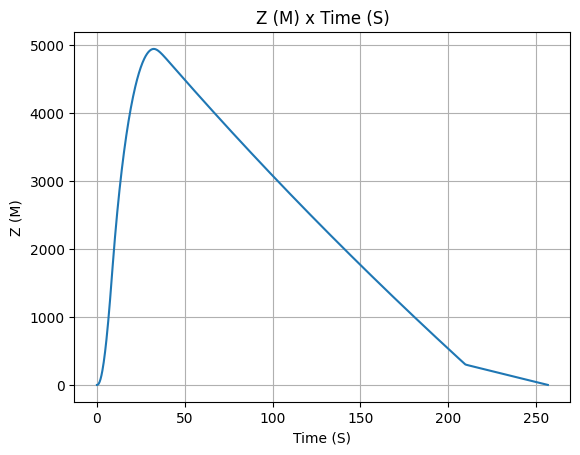

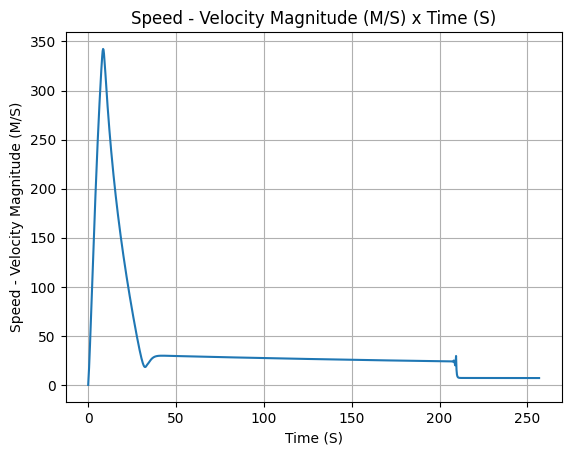

In [ ]:
flight.z.plot()
flight.speed.plot()

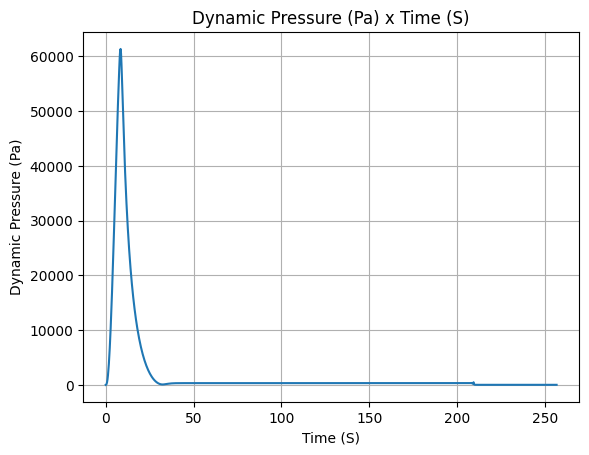

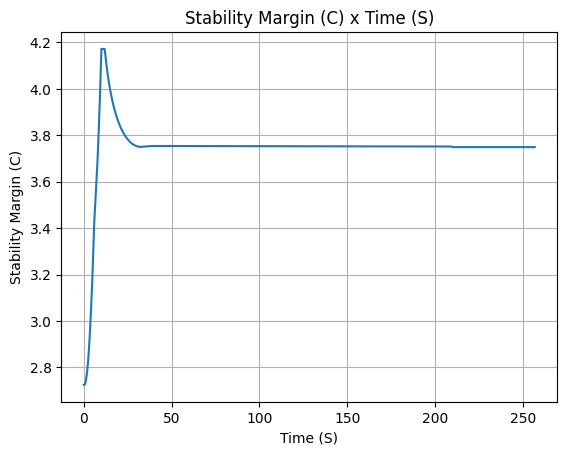

In [ ]:
flight.dynamic_pressure.plot()
flight.stability_margin.plot()

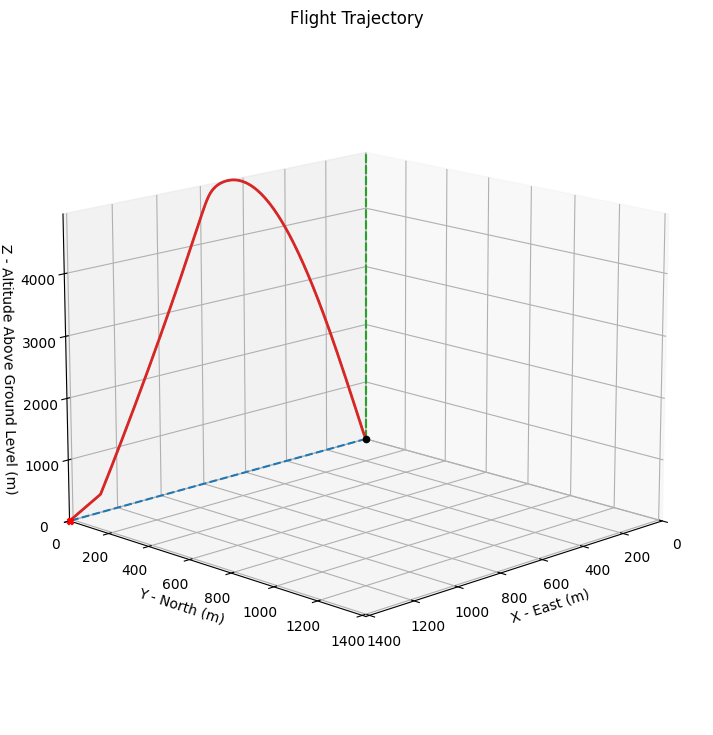

In [ ]:
flight.plots.trajectory_3d()

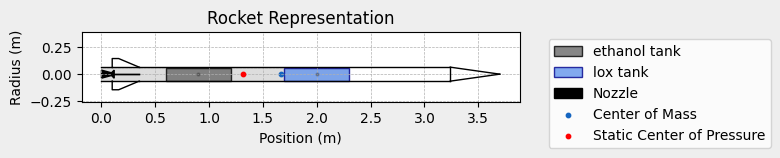

In [ ]:
rocket.draw()

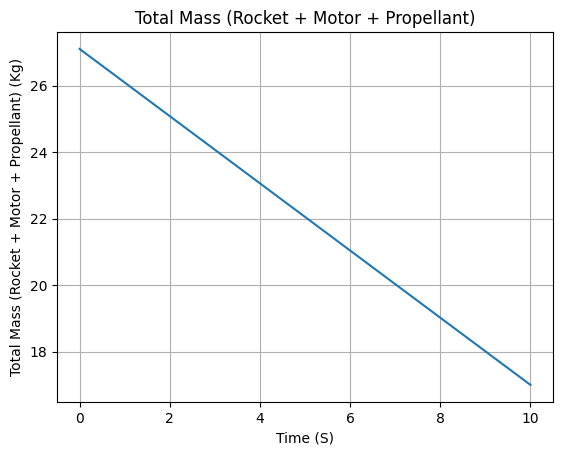

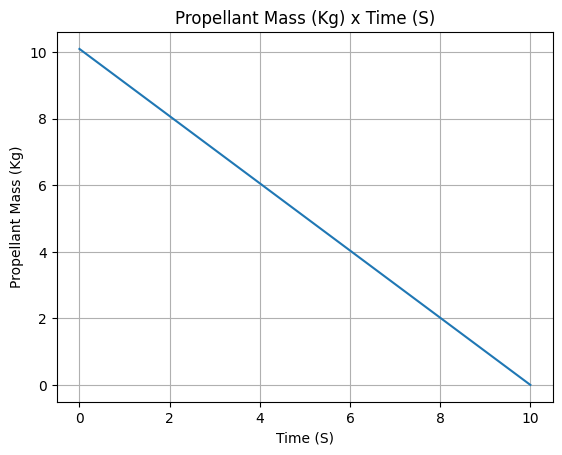

In [ ]:
rocket.plots.total_mass()
motor.propellant_mass.plot()

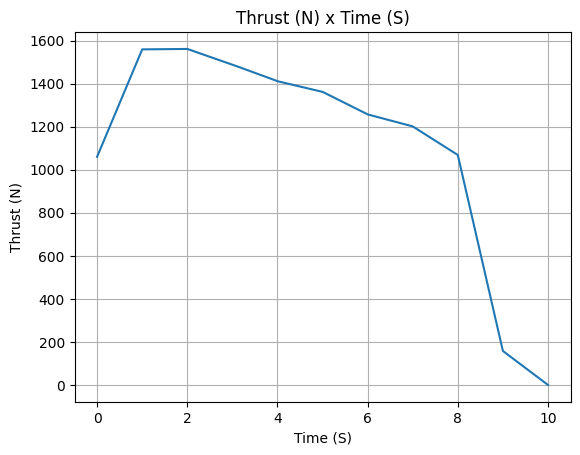

In [ ]:
motor.thrust.plot()

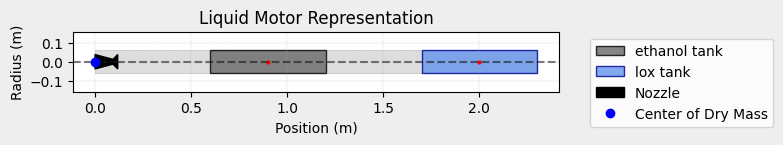

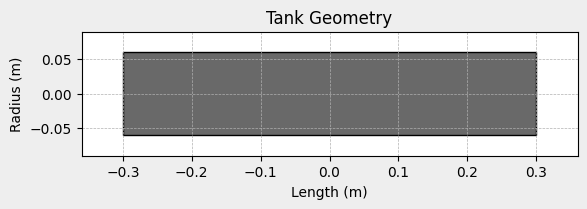

In [ ]:
motor.draw()
ethanol_tank.draw()

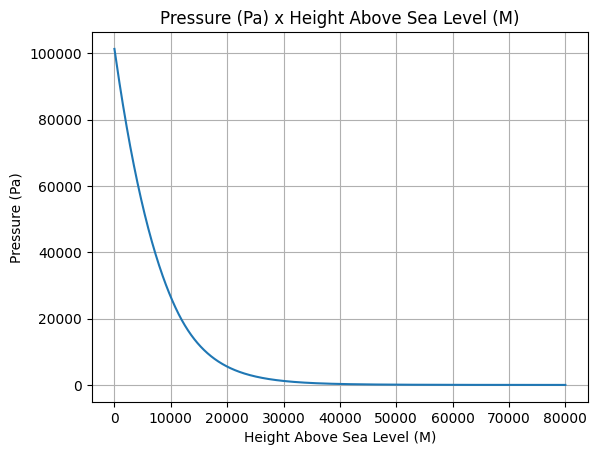

In [ ]:
env.pressure.plot()